# Boston Housing Price Prediction – Exploratory Data Analysis

## Objective
The objective of this project is to explore the Boston Housing dataset,
understand the relationships between different housing features and
house prices, and prepare the data for regression modelling.

## Target Variable
medv – Median value of owner-occupied homes.

In [2]:

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

df = pd.read_csv("boston_data.csv")


In [4]:
df.head(10)    # First 10 rows

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,4,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
3,5,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
4,7,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,12.43,22.9
5,11,7.87,0,0.524,6.377,94.3,6.3467,5,311,15.2,20.45,15.0
6,12,7.87,0,0.524,6.009,82.9,6.2267,5,311,15.2,13.27,18.9
7,13,7.87,0,0.524,5.889,39.0,5.4509,5,311,15.2,15.71,21.7
8,14,8.14,0,0.538,5.949,61.8,4.7075,4,307,21.0,8.26,20.4
9,15,8.14,0,0.538,6.096,84.5,4.4619,4,307,21.0,10.26,18.2


In [5]:
df.tail()      # Last 5 rows



,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
328,500,9.69,0,0.585,5.569,73.5,2.3999,6,391,19.2,15.10,17.5
329,502,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
330,503,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
331,504,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
332,506,11.93,0,0.573,6.030,80.8,2.5050,1,273,21.0,7.88,11.9


In [6]:
df.sample(5)   # Random 5 rows

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
100,149,19.58,0,0.871,5.186,93.8,1.5296,5,403,14.7,28.32,17.8
242,368,18.10,0,0.631,3.863,100.0,1.5106,24,666,20.2,13.33,23.1
311,475,18.10,0,0.584,5.427,95.4,2.4298,24,666,20.2,18.14,13.8
149,217,13.89,1,0.550,5.888,56.0,3.1121,5,276,16.4,13.51,23.3
213,319,9.90,0,0.544,6.382,67.2,3.5325,4,304,18.4,10.36,23.1


In [7]:
df.shape

(333, 12)

In [8]:
df.columns

Index(['ID', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 12 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ID       333 non-null    int64  
 1   indus    333 non-null    float64
 2   chas     333 non-null    int64  
 3   nox      333 non-null    float64
 4   rm       333 non-null    float64
 5   age      333 non-null    float64
 6   dis      333 non-null    float64
 7   rad      333 non-null    int64  
 8   tax      333 non-null    int64  
 9   ptratio  333 non-null    float64
 10  lstat    333 non-null    float64
 11  medv     333 non-null    float64
dtypes: float64(8), int64(4)
memory usage: 31.3 KB


In [10]:

# Statistical summary
df.describe()

,ID,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000
mean,250.951952,11.293483,0.060060,0.557144,6.265619,68.226426,3.709934,9.633634,409.279279,18.448048,12.515435,22.768769
std,147.859438,6.998123,0.237956,0.114955,0.703952,28.133344,1.981123,8.742174,170.841988,2.151821,7.067781,9.173468
min,1.000000,0.740000,0.000000,0.385000,3.561000,6.000000,1.129600,1.000000,188.000000,12.600000,1.730000,5.000000
25%,123.000000,5.130000,0.000000,0.453000,5.884000,45.400000,2.122400,4.000000,279.000000,17.400000,7.180000,17.400000
50%,244.000000,9.900000,0.000000,0.538000,6.202000,76.700000,3.092300,5.000000,330.000000,19.000000,10.970000,21.600000
75%,377.000000,18.100000,0.000000,0.631000,6.595000,93.800000,5.116700,24.000000,666.000000,20.200000,16.420000,25.000000
max,506.000000,27.740000,1.000000,0.871000,8.725000,100.000000,10.710300,24.000000,711.000000,21.200000,37.970000,50.000000


In [11]:
# Check missing values
df.isnull().sum()


ID         0
indus      0
chas       0
nox        0
rm         0
age        0
dis        0
rad        0
tax        0
ptratio    0
lstat      0
medv       0
dtype: int64

In [12]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

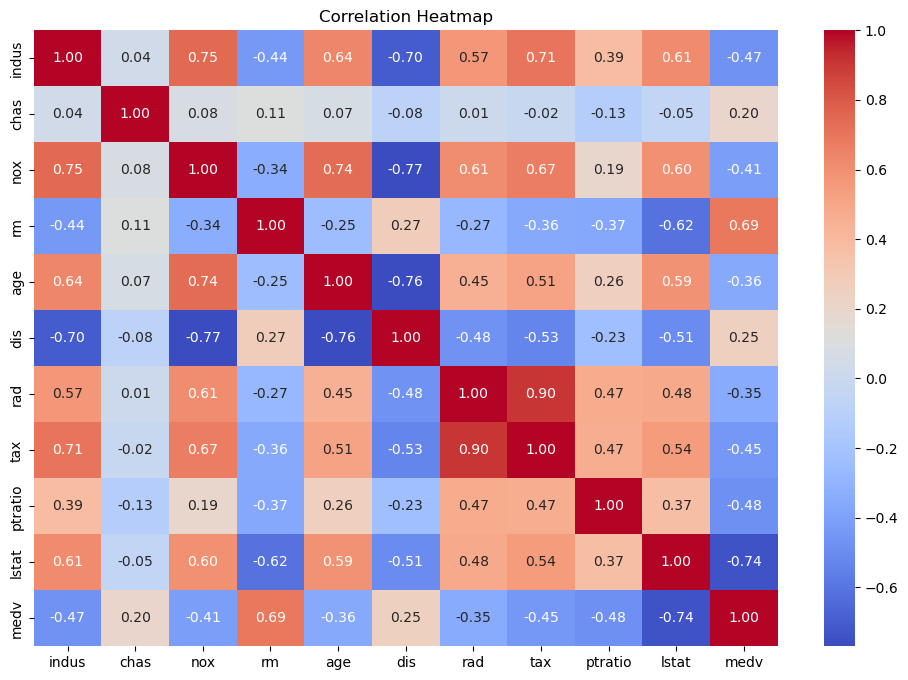

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(df.drop(columns=['ID']).corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()


Relationship with house price (medv)

Positive correlation:
- rm (0.690): More rooms are associated with higher house prices.
- dis (0.249): Weak positive relationship.
- chas (0.204): Weak positive relationship.

Negative correlation:
- lstat (-0.739): Strongest negative relationship.Higher lstat values are associated with lower house prices.
- ptratio (-0.481)
- indus (-0.474)
- tax (-0.448)
- nox (-0.413)
- age (-0.359)
- rad (-0.352)

Important observations
1. rm has the strongest positive correlation with medv.
2. lstat has the strongest negative correlation with medv.
3. ID should not be used as a prediction feature.
4. Correlation does not prove causation.

# Univariate Analysis

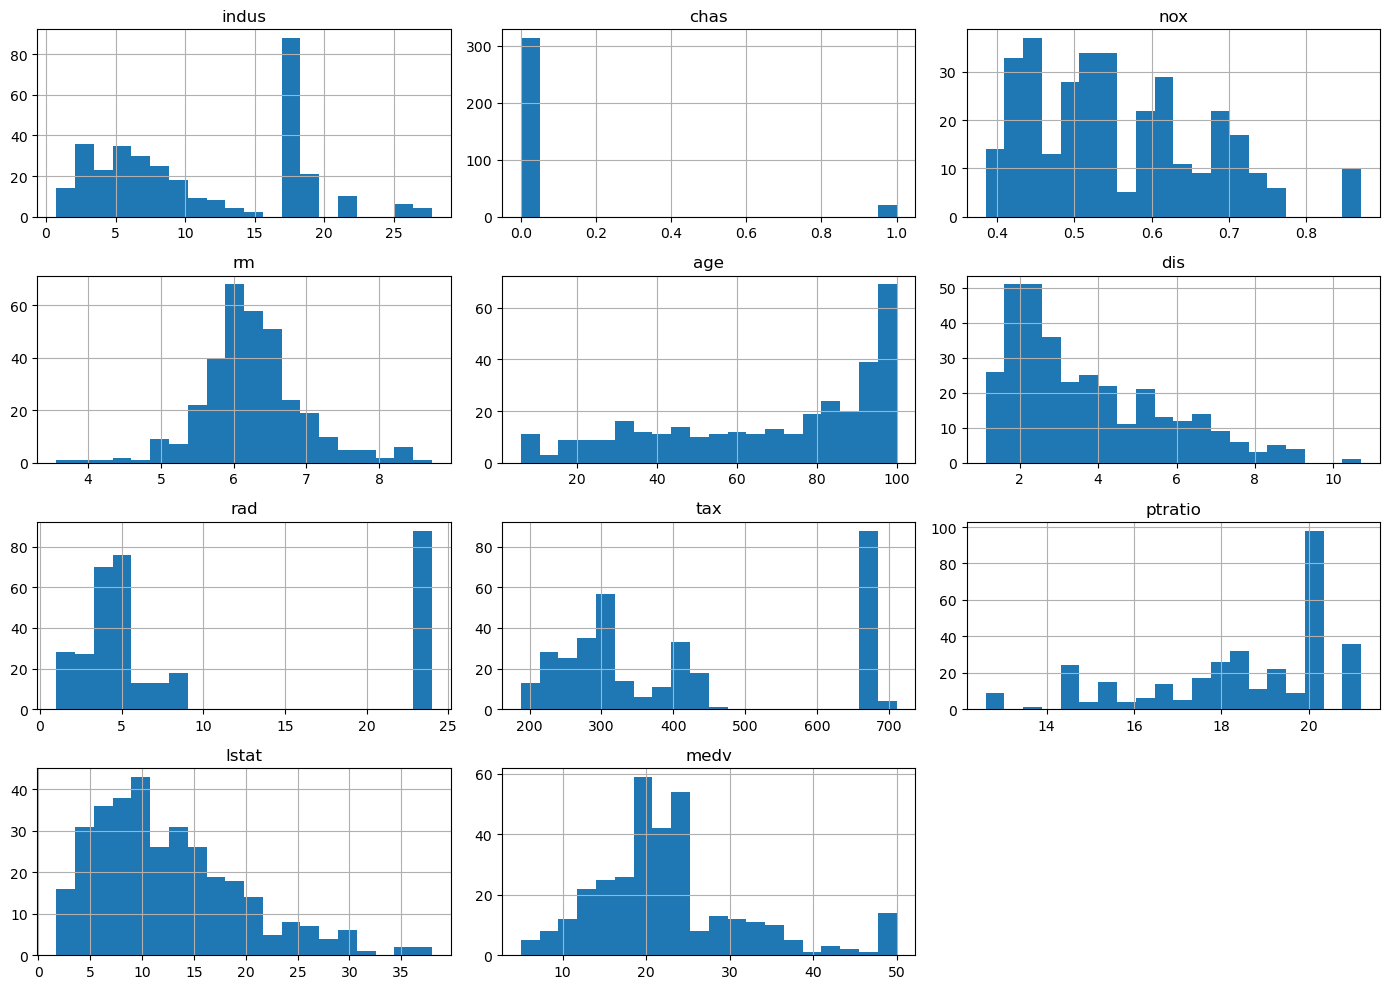

In [14]:
df.drop(columns=['ID']).hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

# Bi-Variate Analysis

In [15]:
df.columns

Index(['ID', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='object')

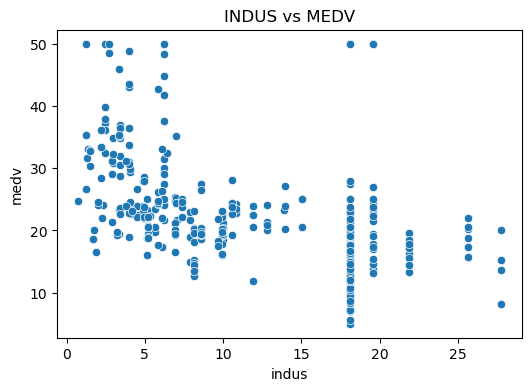

In [16]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='indus', y='medv', data=df)            
plt.title("INDUS vs MEDV")
plt.show()

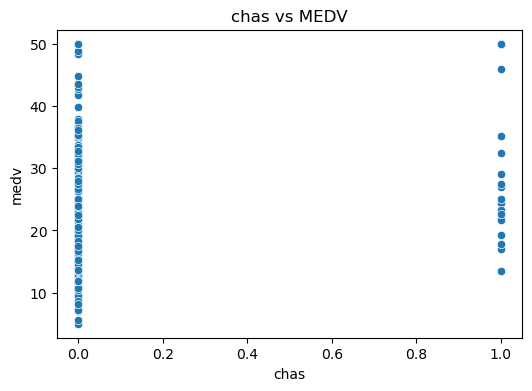

In [17]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='chas', y='medv', data=df)            
plt.title("chas vs MEDV")
plt.show()

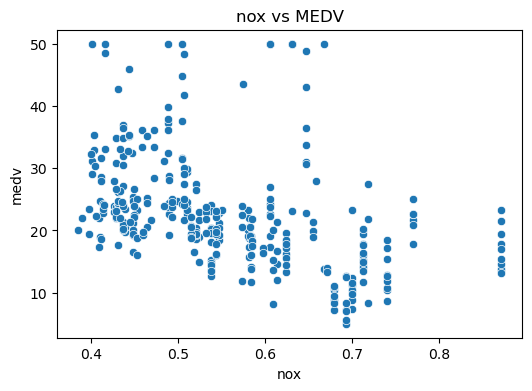

In [18]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='nox', y='medv', data=df)            
plt.title("nox vs MEDV")
plt.show()

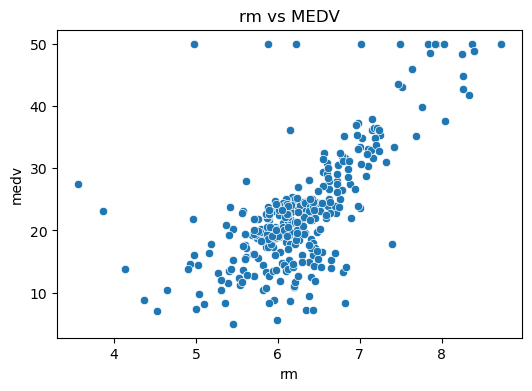

In [19]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='rm', y='medv', data=df)            
plt.title("rm vs MEDV")
plt.show()

# positive correlation

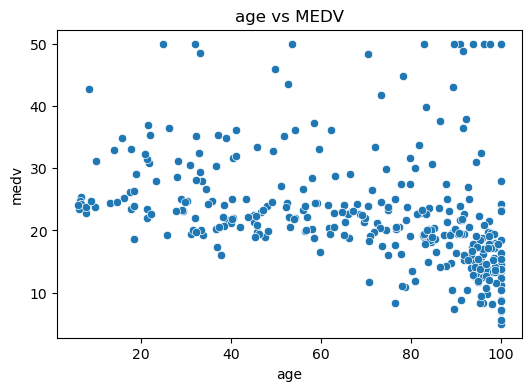

In [20]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='age', y='medv', data=df)            
plt.title("age vs MEDV")
plt.show()

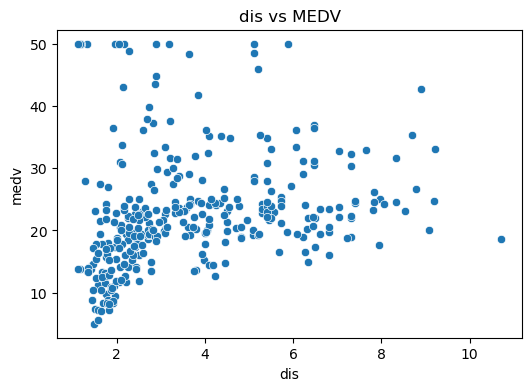

In [21]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='dis', y='medv', data=df)            
plt.title("dis vs MEDV")
plt.show()

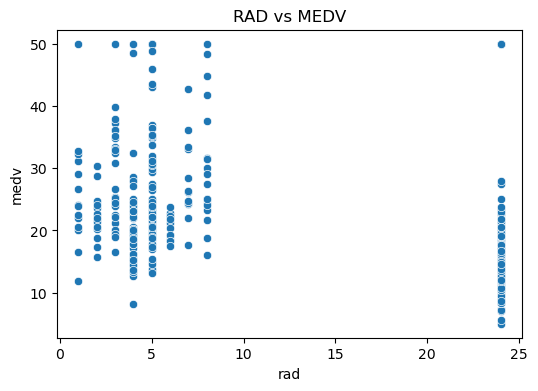

In [22]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='rad', y='medv', data=df)            
plt.title("RAD vs MEDV")
plt.show()

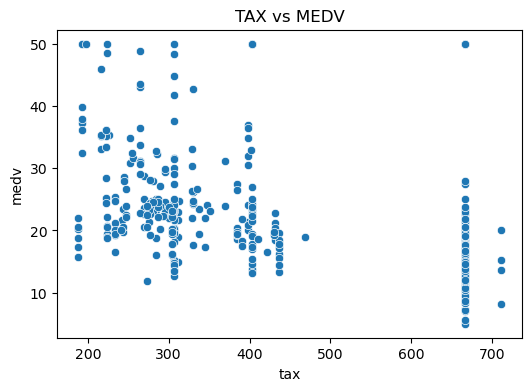

In [23]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='tax', y='medv', data=df)    
plt.title("TAX vs MEDV")
plt.show()

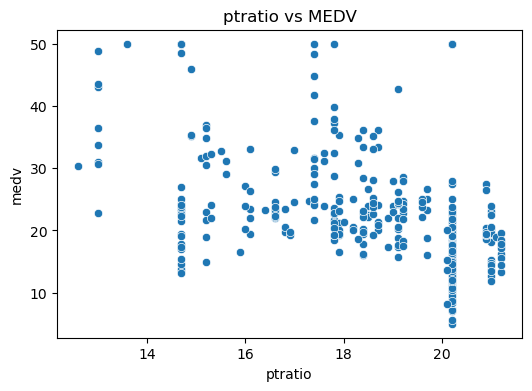

In [24]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='ptratio', y='medv', data=df)            
plt.title("ptratio vs MEDV")
plt.show()

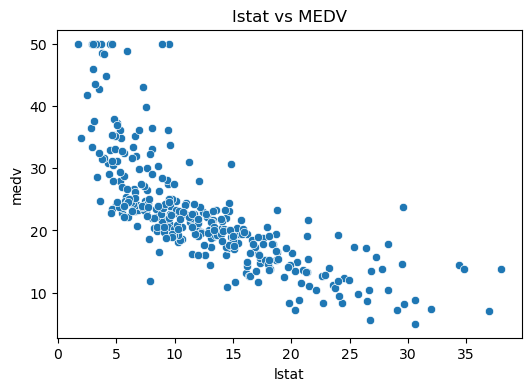

In [25]:
plt.figure(figsize=(6,4))                             
sns.scatterplot(x='lstat', y='medv', data=df)            
plt.title("lstat vs MEDV")
plt.show()

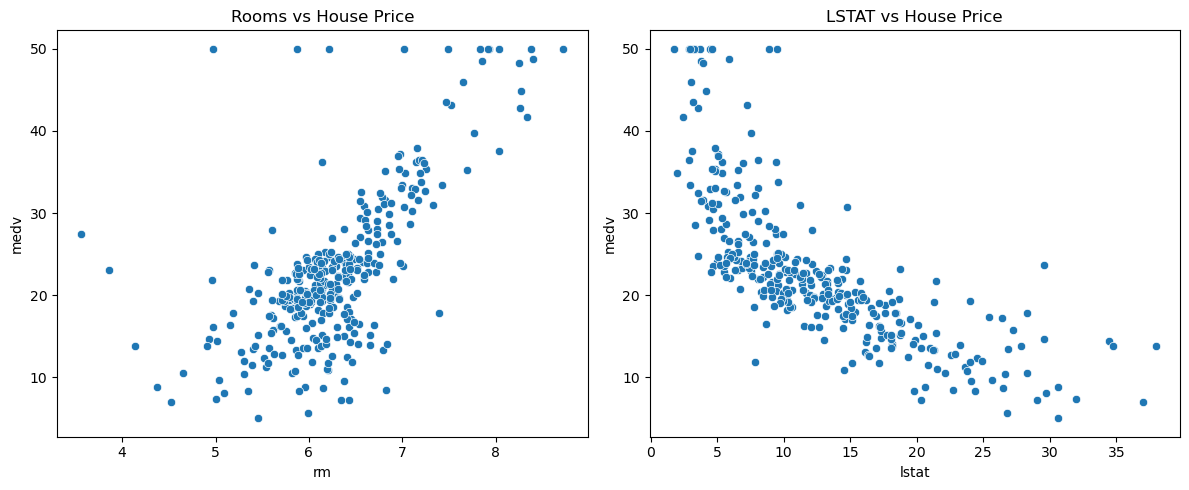

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x='rm', y='medv', ax=axes[0])
axes[0].set_title('Rooms vs House Price')

sns.scatterplot(data=df, x='lstat', y='medv', ax=axes[1])
axes[1].set_title('LSTAT vs House Price')

plt.tight_layout()
plt.show()

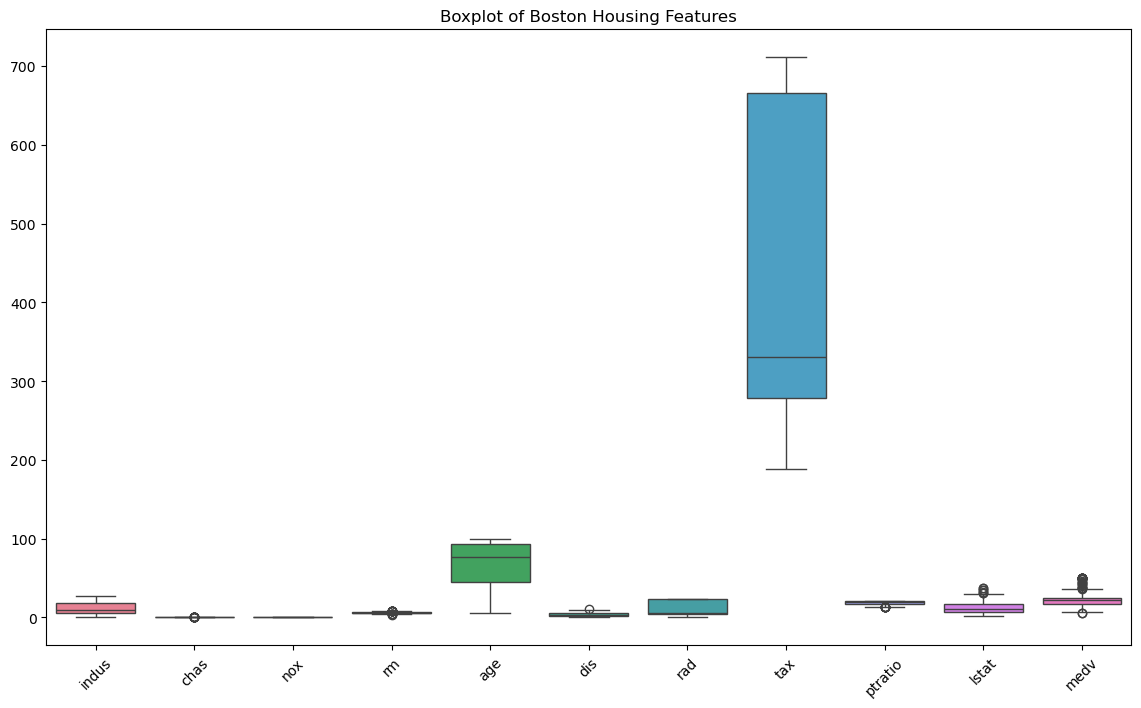

In [27]:
plt.figure(figsize=(14, 8))

sns.boxplot(data=df.drop(columns=['ID']))

plt.xticks(rotation=45)
plt.title("Boxplot of Boston Housing Features")
plt.show()

In [28]:
for col in df.drop(columns=['ID']).columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, ":", count)

indus : 0
chas : 20
nox : 0
rm : 21
age : 0
dis : 1
rad : 0
tax : 0
ptratio : 9
lstat : 7
medv : 28


What do these results mean?

- chas: This is a binary column (0 or 1). These are not actual outliers. Don't remove them.
- rm: 21 unusual room-count values.
- dis: Only 1 unusual value.
- ptratio: 9 unusual values.
- lstat: 7 unusual values.
- medv: 28 unusual house-price values.

Important: Outliers don't necessarily mean incorrect data. They may be genuine observations. We should not delete them automatically, especially from medv, because it is our prediction target.

In [29]:
X = df.drop(columns=['ID', 'medv'])
y = df['medv']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (333, 10)
Target shape: (333,)


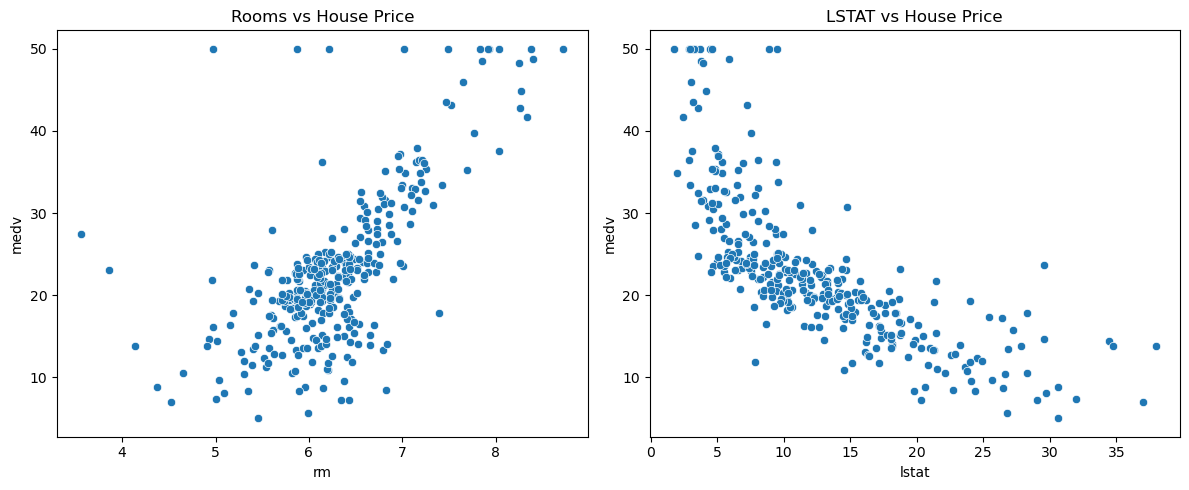

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x='rm', y='medv', ax=axes[0])
axes[0].set_title('Rooms vs House Price')

sns.scatterplot(data=df, x='lstat', y='medv', ax=axes[1])
axes[1].set_title('LSTAT vs House Price')

plt.tight_layout()
plt.show()

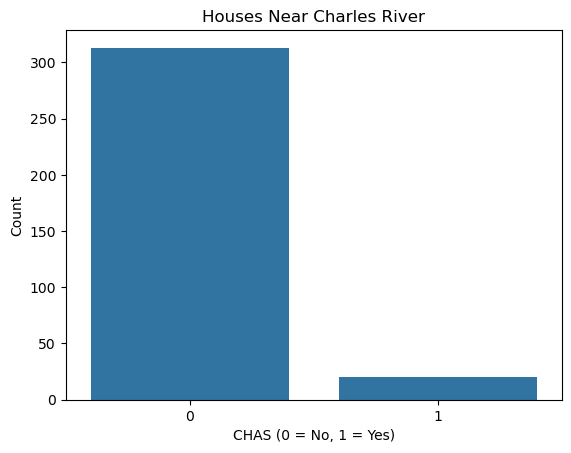

In [31]:
sns.countplot(data=df, x='chas')
plt.title('Houses Near Charles River')
plt.xlabel('CHAS (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# Conclusion of EDA

## Exploratory Data Analysis – Key Findings

1. The dataset contains **333 records and 12 columns**.
2. No missing values or duplicate rows were found.
3. `rm` has a positive correlation with house prices.
4. `lstat` has a strong negative correlation with house prices.
5. Potential outliers were identified in several numerical features.
6. Outliers were retained because they may represent genuine observations.
7. `ID` is an identifier and will not be used for model training.
8. `medv` is the target variable to be predicted.

### Conclusion

EDA helped us understand the dataset, examine feature distributions, identify potential outliers, and explore relationships between input features and house prices.

The dataset is ready for the preprocessing and regression modelling stage.

### Dataset Limitation

This is a historical Boston Housing dataset. Its variables and relationships should not be assumed to represent today's housing market. Some historical demographic variables also require careful ethical consideration.
